SHOOTING METHOD
-----------------------
Initial slope = 0.85091812815051
Final value = 0.999999999999999

 x       Numerical       Exact
0.00     0.000000      0.000000
0.10     0.086098      0.086098
0.20     0.173074      0.173074
0.30     0.261818      0.261818
0.40     0.353236      0.353236
0.51     0.448261      0.448261
0.61     0.547864      0.547864
0.71     0.653061      0.653061
0.81     0.764927      0.764927
0.91     0.884604      0.884604


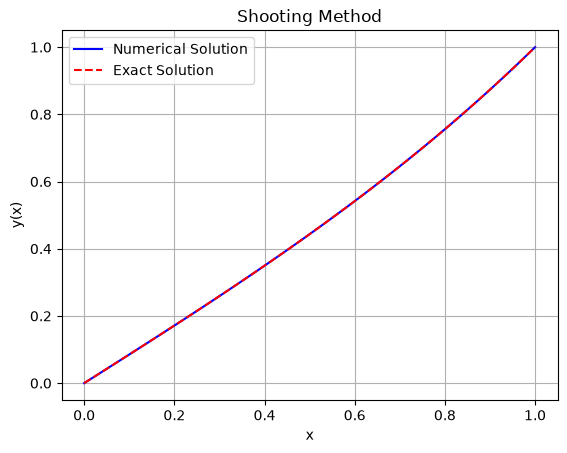

In [4]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar

def model(x, Y):
    y, z = Y
    return [z, y]

a = 0
b = 1
ya = 0
yb = 1

def solve_ode(s):
    return solve_ivp(
        model,
        [a, b],
        [ya, s],
        t_eval=np.linspace(a, b, 100),
        rtol=1e-9,
        atol=1e-11
    )

def residual(s):
    sol = solve_ode(s)
    return sol.y[0, -1] - yb

result = root_scalar(
    residual,
    bracket=[0, 2],
    method='brentq'
)

s = result.root
sol = solve_ode(s)

x = sol.t
y = sol.y[0]

y_exact = np.sinh(x) / np.sinh(1)

print("SHOOTING METHOD")
print("-----------------------")
print("Initial slope =", s)
print("Final value =", y[-1])

print("\n x       Numerical       Exact")
for i in range(0, 100, 10):
    print(f"{x[i]:.2f}     {y[i]:.6f}      {y_exact[i]:.6f}")

plt.plot(x, y, 'b-', label='Numerical Solution')
plt.plot(x, y_exact, 'r--', label='Exact Solution')

plt.xlabel("x")
plt.ylabel("y(x)")
plt.title("Shooting Method")
plt.legend()
plt.grid()
plt.show()
